In [ ]:
!pip install -q pandas numpy nltk scikit-learn matplotlib

In [ ]:
# 4. Implement e-mail spam filtering using text classification algorithm with appropriate dataset.

In [ ]:
# Practical 4: SMS Spam Filtering using KNN

# Step 1: Import required libraries
import urllib.request
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
# Step 2: Download stopwords
nltk.download('stopwords', quiet=True)

True

In [ ]:
# Step 3: Download and load dataset
url = "https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv"

target_path = "spam.csv"

print("Downloading dataset...")

req = urllib.request.Request(
    url,
    headers={'User-Agent': 'Mozilla/5.0'}
)

with urllib.request.urlopen(req) as response:
    with open(target_path, 'wb') as out_file:
        out_file.write(response.read())

print("Download complete!")

df = pd.read_csv(target_path, encoding='latin-1')

# Select first two columns
df = df.iloc[:, :2]

# Rename columns
df.columns = ['label', 'message']

print("\nDataset:")
print(df.head())

print("\nDataset Shape:", df.shape)


Download complete!

Dataset:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Shape: (5572, 2)


In [ ]:
# Step 4: Convert labels into numerical values
df['label'] = df['label'].str.lower().str.strip()

df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

df = df.dropna()


In [ ]:
# Step 5: Text preprocessing
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess(text):

    words = re.findall(
        r'\b[a-zA-Z]+\b',
        str(text).lower()
    )

    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

df['message'] = df['message'].apply(preprocess)

print("\nAfter Text Preprocessing:")
print(df.head())


After Text Preprocessing:
   label                                            message
0      0  go jurong point crazi avail bugi n great world...
1      0                              ok lar joke wif u oni
2      1  free entri wkli comp win fa cup final tkt may ...
3      0                u dun say earli hor u c alreadi say
4      0               nah think goe usf live around though


In [ ]:
# Step 6: Split data into training and testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['message'],
    df['label'],
    test_size=0.20,
    random_state=42,
    stratify=df['label']
)

In [ ]:
# Step 7: Feature extraction using TF-IDF
vectorizer = TfidfVectorizer()

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (4457, 5417)
Testing Data: (1115, 5417)


In [ ]:
# Step 8: Apply KNN algorithm
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean',
    algorithm='brute'
)

knn.fit(X_train, y_train)

KNeighborsClassifier(algorithm='brute', metric='euclidean')

In [ ]:
# Step 9: Predict email categories
y_pred = knn.predict(X_test)

In [ ]:
# Step 10: Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

print("\nKNN Classification Results:")
print("Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Ham', 'Spam'],
        zero_division=0
    )
)


KNN Classification Results:
Accuracy: 92.01793721973094 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.92      1.00      0.96       966
        Spam       1.00      0.40      0.57       149

    accuracy                           0.92      1115
   macro avg       0.96      0.70      0.77      1115
weighted avg       0.93      0.92      0.90      1115




Confusion Matrix:
[[966   0]
 [ 89  60]]


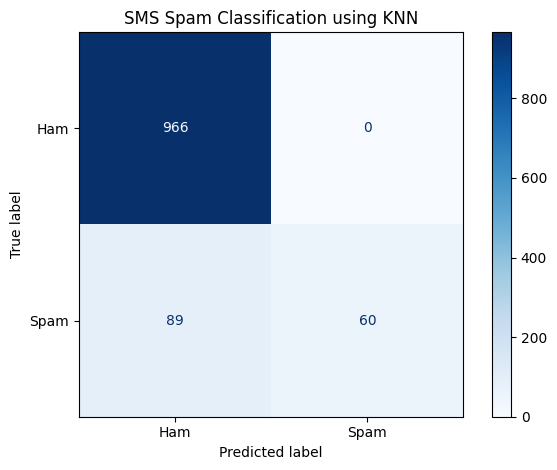

In [ ]:
# Step 11: Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Ham', 'Spam']
)

display.plot(cmap='Blues')
plt.title("SMS Spam Classification using KNN")
plt.tight_layout()
plt.show()

In [ ]:
# Step 12: Test a new message
new_message = [
    "Congratulations! You won a free prize. Claim now!"
]

new_message_processed = [
    preprocess(message) for message in new_message
]

new_message_vector = vectorizer.transform(
    new_message_processed
)

prediction = knn.predict(new_message_vector)

print("\nNew Message Prediction:")

if prediction[0] == 1:
    print("Spam")
else:
    print("Ham")

print("\nProgram completed successfully!")


New Message Prediction:
Ham

Program completed successfully!
